In [62]:
import matplotlib.pyplot as plt
import numpy as np

# Percentage of Gene Records with collisions per source

In [63]:
import sys
from pathlib import Path

# Add output/ to sys.path so you can import from it
sys.path.append(str(Path().resolve().parent / "output"))

In [64]:
from collision_analysis_shared_variables import *

In [65]:
#from 1_alias_primary_collision_analysis: ap_record_count_xxxx
#HGNC, ENSG, NCBI
ap_record_counts = [ap_record_count_hgnc,ap_record_count_ensg,ap_record_count_ncbi]

In [66]:
#from 1_alias_primary_collision_analysis: gene_record_count_xxxx
#HGNC, ENSG, NCBI
total_record_counts = [gene_record_count_hgnc, gene_record_count_ensg, gene_record_count_ncbi]

In [67]:
#from 2_alias_alias_collision_analysis: aa_record_count_xxxx
#HGNC, ENSG, NCBI
aa_record_counts = [aa_record_count_hgnc, aa_record_count_ensg, aa_record_count_ncbi]

In [68]:
both_collision_record_set_hgnc = ap_record_set_hgnc.intersection(aa_record_set_hgnc)
both_collision_record_count_hgnc = len(both_collision_record_set_hgnc)
both_collision_record_count_hgnc

185

In [69]:
both_collision_record_set_ensg = ap_record_set_ensg.intersection(aa_record_set_ensg)
both_collision_record_count_ensg = len(both_collision_record_set_ensg)
both_collision_record_count_ensg

282

In [70]:
both_collision_record_set_ncbi = ap_record_set_ncbi.intersection(aa_record_set_ncbi)
both_collision_record_count_ncbi = len(both_collision_record_set_ncbi)
both_collision_record_count_ncbi

834

In [71]:
both_collision_record_counts = [both_collision_record_count_hgnc, both_collision_record_count_ensg,both_collision_record_count_ncbi]


correct aa and ap record counts so that they don't include the records that are involved in both an ap and aa collision

In [72]:
corrected_aa_record_count_hgnc = aa_record_count_hgnc - both_collision_record_count_hgnc
corrected_aa_record_count_ensg = aa_record_count_ensg - both_collision_record_count_ensg
corrected_aa_record_count_ncbi = aa_record_count_ncbi - both_collision_record_count_ncbi 

In [73]:
corrected_aa_record_counts = [corrected_aa_record_count_hgnc, corrected_aa_record_count_ensg, corrected_aa_record_count_ncbi]

In [74]:
corrected_ap_record_count_hgnc = ap_record_count_hgnc - both_collision_record_count_hgnc
corrected_ap_record_count_ensg = ap_record_count_ensg - both_collision_record_count_ensg
corrected_ap_record_count_ncbi = ap_record_count_ncbi - both_collision_record_count_ncbi 

In [75]:
corrected_ap_record_counts = [corrected_ap_record_count_hgnc,corrected_ap_record_count_ensg,corrected_ap_record_count_ncbi]

In [76]:
hgnc_percent_records_with_ap_collision = (corrected_ap_record_count_hgnc/gene_record_count_hgnc)*100
ensg_percent_records_with_ap_collision = (corrected_ap_record_count_ensg/gene_record_count_ensg)*100
ncbi_percent_records_with_ap_collision = (corrected_ap_record_count_ncbi/gene_record_count_ncbi)*100

In [77]:
hgnc_percent_records_with_aa_collision = (corrected_aa_record_count_hgnc/gene_record_count_hgnc)*100
ensg_percent_records_with_aa_collision = (corrected_aa_record_count_ensg/gene_record_count_ensg)*100
ncbi_percent_records_with_aa_collision = (corrected_aa_record_count_ncbi/gene_record_count_ncbi)*100

In [78]:
hgnc_percent_records_with_both_collision = (both_collision_record_count_hgnc/gene_record_count_hgnc)*100
ensg_percent_records_with_both_collision = (both_collision_record_count_ensg/gene_record_count_ensg)*100
ncbi_percent_records_with_both_collision = (both_collision_record_count_ncbi/gene_record_count_ncbi)*100

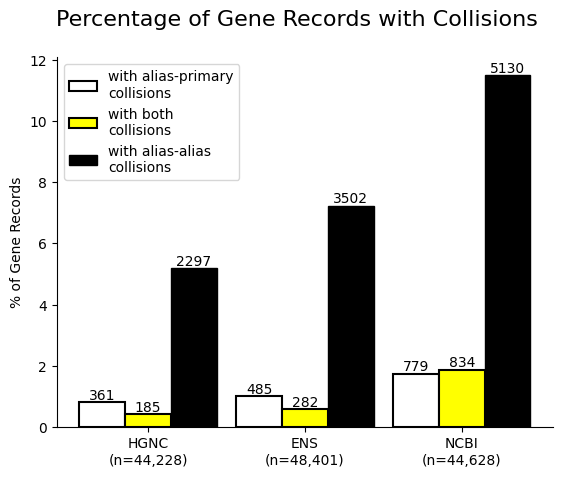

In [79]:
databases = [
    f'HGNC\n(n={gene_record_count_hgnc:,})',
    f'ENS\n(n={gene_record_count_ensg:,})',
    f'NCBI\n(n={gene_record_count_ncbi:,})'
]
percent_records_with_aa_collision = [hgnc_percent_records_with_aa_collision, ensg_percent_records_with_aa_collision, ncbi_percent_records_with_aa_collision]
percent_records_with_ap_collision = [hgnc_percent_records_with_ap_collision, ensg_percent_records_with_ap_collision, ncbi_percent_records_with_ap_collision] 
percent_records_with_both_collision = [hgnc_percent_records_with_both_collision, ensg_percent_records_with_both_collision, ncbi_percent_records_with_both_collision]

x = np.arange(len(databases)) * 1.2

# Width of the bars
width = 0.35

# Plotting the bars
fig, ax = plt.subplots()

# bar3: all white fill with black edge
bar1 = ax.bar(x - .35, percent_records_with_ap_collision, width, label='with alias-primary\ncollisions',
              color='white', edgecolor='black', linewidth=1.5)

# bar2: all yellow fill with black edge
bar2 = ax.bar(x, percent_records_with_both_collision, width, label='with both\ncollisions',
              color='yellow', edgecolor='black', linewidth=1.5)

bar3 = ax.bar(x + .35, percent_records_with_aa_collision, width, label='with alias-alias\ncollisions',
              color='black', edgecolor='black')

# Add raw count labels on bar1
for rect, count in zip(bar1, corrected_ap_record_counts):
    ax.text(rect.get_x() + rect.get_width()/2, rect.get_height(), f'{count}', ha='center', va='bottom')

# Add raw count labels on bar2
for rect, count in zip(bar2, both_collision_record_counts):
    ax.text(rect.get_x() + rect.get_width()/2, rect.get_height(), f'{count}', ha='center', va='bottom')

# Add raw count labels on bar3
for rect, count in zip(bar3, corrected_aa_record_counts):
    ax.text(rect.get_x() + rect.get_width()/2, rect.get_height(), f'{count}', ha='center', va='bottom')

# Labels and title
ax.set_ylabel(f'% of Gene Records')
ax.set_xticks(x)
ax.set_xticklabels(databases)
ax.legend(loc='upper left')

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.suptitle("Percentage of Gene Records with Collisions", fontsize=16)
plt.show()


# Number of Ambiguous Symbols due to collisions per source

In [80]:
# l_ = lowercased
l_aa_ambiguous_symbol_set_hgnc = set(s.lower() for s in aa_ambiguous_symbol_set_hgnc if isinstance(s, str))
l_aa_ambiguous_symbol_set_ensg = set(s.lower() for s in aa_ambiguous_symbol_set_ensg if isinstance(s, str))
l_aa_ambiguous_symbol_set_ncbi = set(s.lower() for s in aa_ambiguous_symbol_set_ncbi if isinstance(s, str))

l_ap_ambiguous_symbol_set_hgnc = set(s.lower() for s in ap_ambiguous_symbol_set_hgnc if isinstance(s, str))
l_ap_ambiguous_symbol_set_ensg = set(s.lower() for s in ap_ambiguous_symbol_set_ensg if isinstance(s, str))
l_ap_ambiguous_symbol_set_ncbi = set(s.lower() for s in ap_ambiguous_symbol_set_ncbi if isinstance(s, str))

In [81]:
both_collision_ambiguous_symbol_count_hgnc = len(l_aa_ambiguous_symbol_set_hgnc.intersection(l_ap_ambiguous_symbol_set_hgnc))
both_collision_ambiguous_symbol_count_ensg = len(l_aa_ambiguous_symbol_set_ensg.intersection(l_ap_ambiguous_symbol_set_ensg))
both_collision_ambiguous_symbol_count_ncbi = len(l_aa_ambiguous_symbol_set_ncbi.intersection(l_ap_ambiguous_symbol_set_ncbi))

In [82]:
l_aa_ambiguous_symbol_count_hgnc = len(l_aa_ambiguous_symbol_set_hgnc)
l_aa_ambiguous_symbol_count_ensg = len(l_aa_ambiguous_symbol_set_ensg)
l_aa_ambiguous_symbol_count_ncbi = len(l_aa_ambiguous_symbol_set_ncbi)

l_ap_ambiguous_symbol_count_hgnc = len(l_ap_ambiguous_symbol_set_hgnc)
l_ap_ambiguous_symbol_count_ensg = len(l_ap_ambiguous_symbol_set_ensg)
l_ap_ambiguous_symbol_count_ncbi = len(l_ap_ambiguous_symbol_set_ncbi)

In [83]:
aa_ambiguous_symbol_count = [l_aa_ambiguous_symbol_count_hgnc, l_aa_ambiguous_symbol_count_ensg, l_aa_ambiguous_symbol_count_ncbi]
ap_ambiguous_symbol_count = [l_ap_ambiguous_symbol_count_hgnc, l_ap_ambiguous_symbol_count_ensg, l_ap_ambiguous_symbol_count_ncbi]

In [84]:
both_collision_ambiguous_symbol_count = [both_collision_ambiguous_symbol_count_hgnc, both_collision_ambiguous_symbol_count_ensg, both_collision_ambiguous_symbol_count_ncbi]

In [85]:
corrected_aa_ambiguous_symbol_count = [(l_aa_ambiguous_symbol_count_hgnc - both_collision_ambiguous_symbol_count_hgnc), (l_aa_ambiguous_symbol_count_ensg - both_collision_ambiguous_symbol_count_ensg), (l_aa_ambiguous_symbol_count_ncbi - both_collision_ambiguous_symbol_count_ncbi)]
corrected_ap_ambiguous_symbol_count = [(l_ap_ambiguous_symbol_count_hgnc - both_collision_ambiguous_symbol_count_hgnc), (l_ap_ambiguous_symbol_count_ensg - both_collision_ambiguous_symbol_count_ensg), (l_ap_ambiguous_symbol_count_ncbi - both_collision_ambiguous_symbol_count_ncbi)]

In [86]:
both_collision_ambiguous_symbol_count_hgnc

49

In [87]:
l_aa_ambiguous_symbol_count_hgnc

1230

In [88]:
l_ap_ambiguous_symbol_count_hgnc

492

In [89]:
corrected_aa_ambiguous_symbol_count

[1181, 1557, 3478]

In [91]:
l_primary_symbol_set_hgnc = set(s.lower() for s in primary_symbol_set_hgnc if isinstance(s, str))
l_primary_symbol_set_ensg = set(s.lower() for s in primary_symbol_set_ensg if isinstance(s, str))
l_primary_symbol_set_ncbi = set(s.lower() for s in primary_symbol_set_ncbi if isinstance(s, str))

l_alias_symbol_set_hgnc = set(s.lower() for s in alias_symbol_set_hgnc if isinstance(s, str))
l_alias_symbol_set_ensg = set(s.lower() for s in alias_symbol_set_ensg if isinstance(s, str))
l_alias_symbol_set_ncbi = set(s.lower() for s in alias_symbol_set_ncbi if isinstance(s, str))

l_total_symbol_count_hgnc = len(l_primary_symbol_set_hgnc | l_alias_symbol_set_hgnc)
l_total_symbol_count_ensg = len(l_primary_symbol_set_ensg | l_alias_symbol_set_ensg)
l_total_symbol_count_ncbi = len(l_primary_symbol_set_ncbi | l_alias_symbol_set_ncbi)

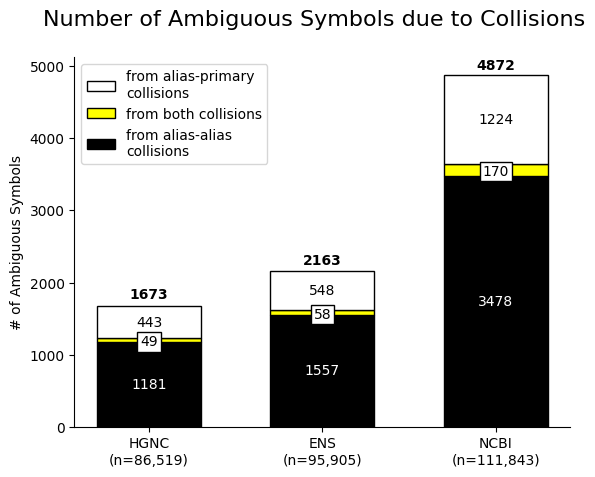

In [92]:
databases = [
    f'HGNC\n(n={l_total_symbol_count_hgnc:,})',
    f'ENS\n(n={l_total_symbol_count_ensg:,})',
    f'NCBI\n(n={l_total_symbol_count_ncbi:,})'
]
x = np.arange(len(databases))
width = 0.6

fig, ax = plt.subplots()

# Use black, yellow, white colors
bar1 = ax.bar(x, corrected_aa_ambiguous_symbol_count, width, label='from alias-alias\ncollisions', color='black', edgecolor='black')
bar2 = ax.bar(x, both_collision_ambiguous_symbol_count, width, bottom=corrected_aa_ambiguous_symbol_count, label='from both collisions', color='yellow', edgecolor='black')
bottom_1_2 = np.array(corrected_aa_ambiguous_symbol_count) + np.array(both_collision_ambiguous_symbol_count)
bar3 = ax.bar(x, corrected_ap_ambiguous_symbol_count, width, bottom=bottom_1_2, label='from alias-primary\ncollisions', color='white', edgecolor='black')

def add_labels(bars, bottoms, values, text_color):
    for rect, bottom, value in zip(bars, bottoms, values):
        height = rect.get_height()
        ax.text(
            rect.get_x() + rect.get_width() / 2,
            bottom + height / 2,
            str(value),
            ha='center', va='center',
            fontsize=10,
            color=text_color,
        )
def add_labels_with_box(bars, bottoms, values, text_color):
    for rect, bottom, value in zip(bars, bottoms, values):
        height = rect.get_height()
        ax.text(
            rect.get_x() + rect.get_width() / 2,
            bottom + height / 2 - 25,
            str(value),
            ha='center', va='center',
            fontsize=10,
            color=text_color,
            bbox=dict(facecolor='white', edgecolor='black', boxstyle='square,pad=0.2')
        )

# Add labels with color matching the background color for contrast
add_labels(bar1, np.zeros(len(corrected_aa_ambiguous_symbol_count)), corrected_aa_ambiguous_symbol_count, 'white')  
add_labels_with_box(bar2, corrected_aa_ambiguous_symbol_count, both_collision_ambiguous_symbol_count, 'black')               
add_labels(bar3, bottom_1_2, corrected_ap_ambiguous_symbol_count, 'black')             

totals = np.array(corrected_aa_ambiguous_symbol_count) + np.array(corrected_ap_ambiguous_symbol_count) + np.array(both_collision_ambiguous_symbol_count)

for i, total in enumerate(totals):
    offsets = [60, 50,40]
    ax.text(
        x[i],                 
        total + offsets[i],          
        str(total),           
        ha='center', va='bottom',
        fontsize=10,
        fontweight='bold'
    )

ax.set_ylabel(f'# of Ambiguous Symbols')
ax.set_xticks(x)
ax.set_xticklabels(databases)
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], labels[::-1], loc='upper left')

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)


plt.suptitle("Number of Ambiguous Symbols due to Collisions", fontsize=16)
plt.show()
